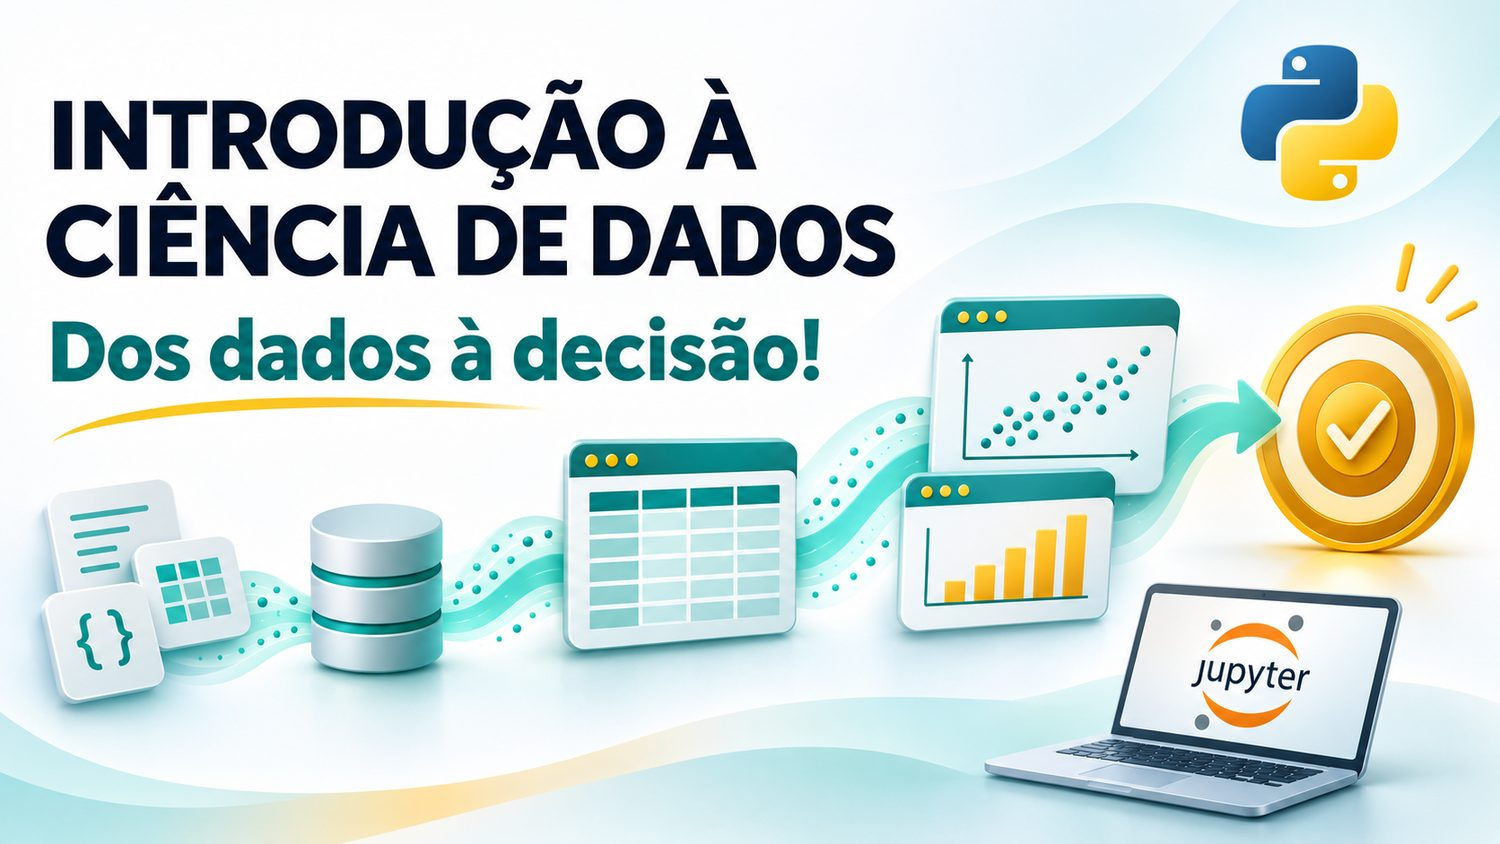

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_5_modelos_lineares/01_Regressao_Linear_Simples.ipynb)

# Capítulo 1 – Regressão linear simples

A regressão linear é o modelo mais antigo e mais usado para prever um número. Já a usámos nos módulos anteriores sem a abrir. Neste capítulo construímo-la de raiz no caso mais simples, com um só atributo: uma **reta**. Tudo o que vem a seguir neste módulo (vários atributos, classificação, regularização) é uma extensão desta ideia.

> **Objetivos:** escrever a equação de uma reta e dar significado ao declive e à ordenada na origem; definir resíduo e erro quadrático; perceber o que são os mínimos quadrados; calcular a reta de raiz com médias, variância e covariância; interpretar o R²; usar os resíduos para ver quando uma reta não chega; conhecer os cuidados ao interpretar e ao extrapolar.

**Pré-requisitos:** módulo 4 (treino, teste e linha de base) e o capítulo 5 do módulo 3 (correlação). A sintaxe do scikit-learn está em [Scikit-Learn: fundamentos](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python/nivel_2_avancado/N2_03_ScikitLearn_Fundamentos.ipynb).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

## O caso deste módulo: quanto vai produzir este telhado?

Uma empresa instala painéis solares em casas. Antes de cada instalação tem de dizer ao cliente **quanta eletricidade os painéis vão produzir por ano**: é desse número que depende a poupança prometida. A empresa tem os registos de produção de 1 500 instalações já feitas.

Os dados são sintéticos.

In [2]:
def gerar_instalacoes(n=1500, semente=61):
    """Gera instalações solares residenciais de uma empresa fictícia (dados sintéticos)."""
    rng = np.random.default_rng(semente)
    potencia = rng.gamma(4.0, 1.1, n).clip(1.5, 12).round(1)
    zona = rng.choice(["norte", "centro", "sul"], n, p=[0.35, 0.4, 0.25])
    orientacao = rng.choice(["sul", "este", "oeste"], n, p=[0.55, 0.22, 0.23])
    inclinacao = rng.normal(28, 8, n).clip(5, 50).round()
    sombra = (rng.beta(1.2, 6, n) * 60).round()
    idade = rng.integers(0, 13, n)
    sol = pd.Series(zona).map({"norte": 1280, "centro": 1420, "sul": 1570}).to_numpy()              # kWh por kWp, por ano
    fator = (pd.Series(orientacao).map({"sul": 1.0, "este": 0.86, "oeste": 0.84}).to_numpy() * (1 - 0.00035 * (inclinacao - 32) ** 2)
             * (1 - 0.009 * sombra) * (1 - 0.006 * idade))
    producao = potencia * sol * fator * rng.normal(1, 0.05, n)
    return pd.DataFrame({"potencia_kwp": potencia, "zona": zona, "orientacao": orientacao, "inclinacao_graus": inclinacao,
                         "sombra_pct": sombra, "idade_anos": idade, "producao_kwh": producao.round(-1)})


instalacoes = gerar_instalacoes()
instalacoes.head()

,potencia_kwp,zona,orientacao,inclinacao_graus,sombra_pct,idade_anos,producao_kwh
0,3.0,centro,este,22.0,13.0,0,3280.0
1,1.5,sul,sul,34.0,27.0,7,1720.0
2,6.1,centro,sul,30.0,9.0,7,7850.0
3,3.0,centro,sul,28.0,2.0,7,3670.0
4,2.2,centro,sul,26.0,29.0,2,2260.0


| Coluna | Significado |
| --- | --- |
| `potencia_kwp` | Potência instalada, em quilowatts-pico (cresce com o número de painéis) |
| `zona` | Norte, centro ou sul do país |
| `orientacao` | Para onde está virado o telhado: sul, este ou oeste |
| `inclinacao_graus` | Inclinação do telhado |
| `sombra_pct` | Percentagem do dia em que os painéis estão à sombra |
| `idade_anos` | Idade da instalação |
| `producao_kwh` | Eletricidade produzida no último ano, em kWh (o alvo) |

Neste capítulo usamos **um só atributo**: a potência instalada. Separamos já os dados de teste.

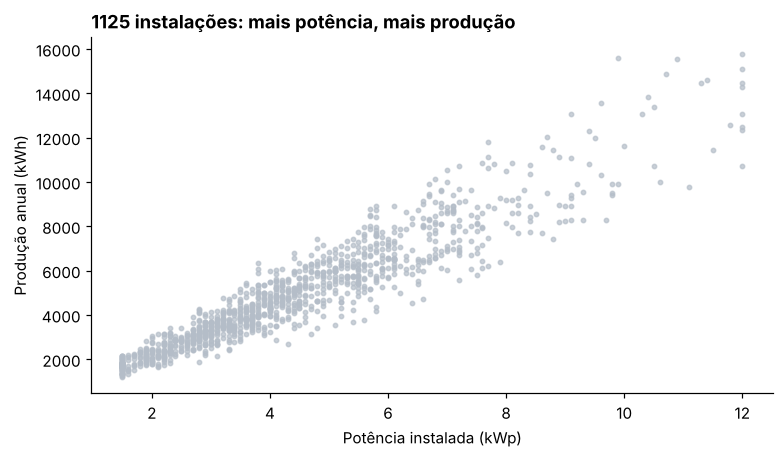

In [3]:
from sklearn.model_selection import train_test_split

treino, teste = train_test_split(instalacoes, test_size=0.25, random_state=0)
x, y = treino["potencia_kwp"].to_numpy(), treino["producao_kwh"].to_numpy()

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.scatter(x, y, s=8, color=CINZA, alpha=0.7)
ax.set_xlabel("Potência instalada (kWp)")
ax.set_ylabel("Produção anual (kWh)")
ax.set_title(f"{len(treino)} instalações: mais potência, mais produção")
plt.show()

A relação é clara e parece seguir uma linha reta: cada quilowatt a mais acrescenta, mais ou menos, a mesma quantidade de energia. É a situação ideal para uma regressão linear.

## Uma reta tem dois números

> **produção prevista = a + b × potência**

| Parâmetro | Nome | Significado geral | Neste caso |
| --- | --- | --- | --- |
| **b** | Declive | Quanto muda a previsão quando o atributo aumenta uma unidade | kWh a mais por cada kWp a mais |
| **a** | Ordenada na origem (ou interceção) | A previsão quando o atributo vale zero | A produção de uma instalação sem painéis |

«Treinar» o modelo é escolher os valores de `a` e de `b`. Para escolher, é preciso dizer o que é uma reta **boa**.

## O que é uma boa reta?

Para cada instalação, o **resíduo** é a diferença entre a produção real e a prevista pela reta. Uma boa reta tem resíduos pequenos.

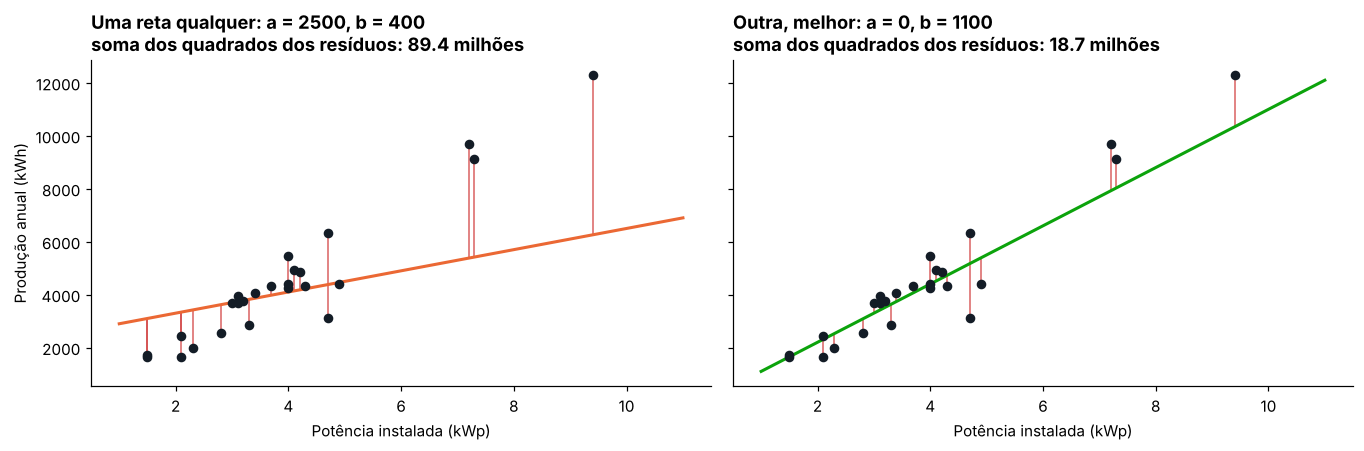

In [4]:
amostra = treino.sample(25, random_state=3)
xs, ys = amostra["potencia_kwp"].to_numpy(), amostra["producao_kwh"].to_numpy()
retas = [("Uma reta qualquer", 2500.0, 400.0, LARANJA), ("Outra, melhor", 0.0, 1100.0, BOM)]

fig, eixos = plt.subplots(1, 2, figsize=(12.5, 4.2), sharey=True)
for ax, (titulo, a, b, cor) in zip(eixos, retas):
    previsto = a + b * xs
    ax.vlines(xs, previsto, ys, color=MAU, lw=1, alpha=0.8)
    ax.scatter(xs, ys, s=28, color=TINTA, zorder=3)
    ax.plot([1, 11], [a + b * 1, a + b * 11], color=cor, lw=2)
    ax.set_xlabel("Potência instalada (kWp)")
    ax.set_title(f"{titulo}: a = {a:.0f}, b = {b:.0f}\nsoma dos quadrados dos resíduos: {np.sum((ys - previsto) ** 2) / 1e6:.1f} milhões")
eixos[0].set_ylabel("Produção anual (kWh)")
plt.tight_layout()
plt.show()

Os traços vermelhos são os resíduos de 25 instalações. Para resumir todos num só número não basta somá-los: os positivos anulariam os negativos. Somam-se os seus **quadrados**.

> A reta dos **mínimos quadrados** é a que torna mínima a soma dos quadrados dos resíduos.

Elevar ao quadrado tem duas consequências: o sinal deixa de contar, e os erros grandes pesam muito mais do que os pequenos (um resíduo duplo conta o quádruplo). A segunda torna a reta sensível a valores extremos, como veremos.

### A procura, vista como uma paisagem

Cada par (a, b) é uma reta, e cada reta tem a sua soma de quadrados. Podemos desenhar esse valor para muitos pares.

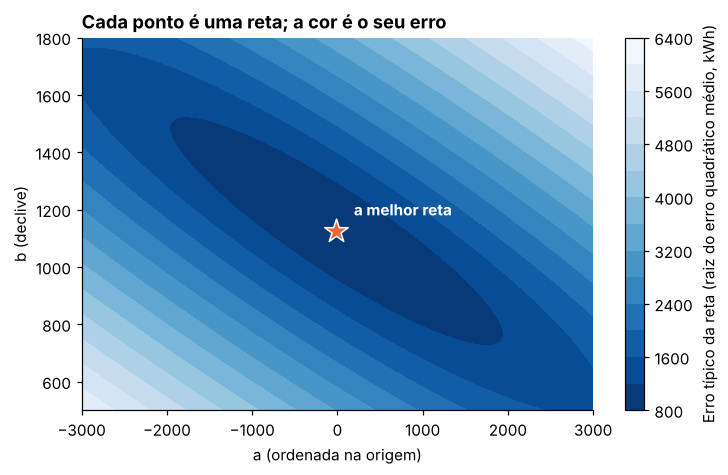

In [5]:
valores_a, valores_b = np.linspace(-3000, 3000, 140), np.linspace(500, 1800, 140)
A, B = np.meshgrid(valores_a, valores_b)
erro = ((y[None, None, :] - (A[:, :, None] + B[:, :, None] * x[None, None, :])) ** 2).mean(axis=2)

fig, ax = plt.subplots(figsize=(7.5, 4.4))
niveis = ax.contourf(A, B, np.sqrt(erro), levels=14, cmap="Blues_r")
fig.colorbar(niveis, ax=ax, label="Erro típico da reta (raiz do erro quadrático médio, kWh)")
i, j = np.unravel_index(erro.argmin(), erro.shape)
ax.scatter([A[i, j]], [B[i, j]], marker="*", s=260, color=LARANJA, edgecolor="white", zorder=3)
ax.annotate("a melhor reta", (A[i, j], B[i, j]), textcoords="offset points", xytext=(12, 10), color="white", fontweight="bold")
ax.set_xlabel("a (ordenada na origem)")
ax.set_ylabel("b (declive)")
ax.grid(False)
ax.set_title("Cada ponto é uma reta; a cor é o seu erro")
plt.show()

A paisagem tem a forma de uma **taça**, com um único ponto mais baixo. Não há mínimos locais onde ficar preso, ao contrário do que acontece com outros modelos. É uma das razões da popularidade da regressão linear: a melhor reta existe, é única e pode ser calculada diretamente.

O vale é alongado na diagonal: uma reta com um declive um pouco maior e uma ordenada um pouco menor erra quase o mesmo. Os dois parâmetros compensam-se.

## Calcular a reta de raiz

Não é preciso procurar na paisagem. O ponto mais baixo tem uma fórmula, que usa três quantidades do módulo 3:

> **b = covariância(x, y) ÷ variância(x)**
>
> **a = média(y) − b × média(x)**

A **covariância** mede como duas variáveis variam em conjunto: é a média dos produtos dos desvios de cada uma em relação à sua média. É positiva quando valores altos de uma acompanham valores altos da outra.

In [6]:
def reta_dos_minimos_quadrados(x, y):
    """Devolve (a, b) da reta y = a + b·x que minimiza a soma dos quadrados dos resíduos."""
    desvios_x, desvios_y = x - x.mean(), y - y.mean()
    covariancia = (desvios_x * desvios_y).mean()
    variancia = (desvios_x ** 2).mean()
    b = covariancia / variancia
    a = y.mean() - b * x.mean()
    return a, b


a, b = reta_dos_minimos_quadrados(x, y)
print(f"Reta: produção = {a:.0f} + {b:.0f} × potência")

Reta: produção = -10 + 1125 × potência


In [7]:
from sklearn.linear_model import LinearRegression

oficial = LinearRegression().fit(treino[["potencia_kwp"]], treino["producao_kwh"])
print(f"scikit-learn: a = {oficial.intercept_:.2f}, b = {oficial.coef_[0]:.2f}")
print(f"A nossa:      a = {a:.2f}, b = {b:.2f}")

scikit-learn: a = -9.62, b = 1124.63
A nossa:      a = -9.62, b = 1124.63


Os dois resultados coincidem. No scikit-learn, a ordenada na origem fica em `intercept_` e os declives em `coef_`.

A segunda fórmula tem uma consequência que vale a pena fixar: **a reta passa sempre pelo ponto das médias**. Para uma instalação com a potência média, prevê a produção média.

### Ler os dois números

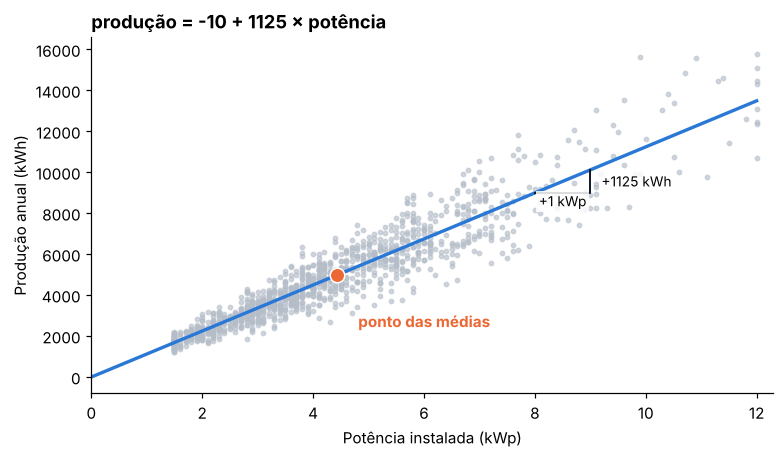

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.scatter(x, y, s=8, color=CINZA, alpha=0.6)
ax.plot([0, 12], [a, a + b * 12], color=AZUL, lw=2.2)
ax.scatter([x.mean()], [y.mean()], s=90, color=LARANJA, zorder=4, edgecolor="white")
ax.annotate("ponto das médias", (x.mean(), y.mean()), textcoords="offset points", xytext=(14, -34), color=LARANJA, fontweight="bold", bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.85, "pad": 1.5})
ax.plot([8, 9, 9], [a + b * 8, a + b * 8, a + b * 9], color=TINTA, lw=1.3)
caixa_branca = {"facecolor": "white", "edgecolor": "none", "alpha": 0.85, "pad": 1.5}
ax.text(8.5, a + b * 8 - 650, "+1 kWp", ha="center", fontsize=9, bbox=caixa_branca)
ax.text(9.2, a + b * 8.5, f"+{b:.0f} kWh", va="center", fontsize=9, bbox=caixa_branca)
ax.set_xlim(0, 12.3)
ax.set_xlabel("Potência instalada (kWp)")
ax.set_ylabel("Produção anual (kWh)")
ax.set_title(f"produção = {a:.0f} + {b:.0f} × potência")
plt.show()

- **O declive** diz que, em média, cada kWp instalado a mais corresponde a cerca de 1 100 kWh a mais por ano. É um número com unidade (kWh por kWp), e é o que a empresa pode usar para dimensionar uma instalação.
- **A ordenada na origem** é a previsão para uma potência de zero. Aqui fica perto de zero, o que faz sentido: sem painéis não há produção. Muitas vezes **não tem interpretação**: se nenhuma observação tem o atributo perto de zero, é apenas o valor que faz a reta passar à altura certa.

O declive mede uma **associação média** nos dados. Não diz que acrescentar um quilowatt a uma instalação concreta lhe dará exatamente este ganho, nem que a potência é a única causa da produção.

### Declive e correlação

A correlação de Pearson (módulo 3) e o declive são parentes próximos:

> **b = r × desvio padrão(y) ÷ desvio padrão(x)**

In [9]:
r = np.corrcoef(x, y)[0, 1]
print(f"Correlação: r = {r:.3f}")
print(f"r × dp(y) ÷ dp(x) = {r * y.std() / x.std():.1f}   |   declive: {b:.1f}")

Correlação: r = 0.940
r × dp(y) ÷ dp(x) = 1124.6   |   declive: 1124.6


A correlação diz **quão bem** os pontos seguem uma reta, entre −1 e 1, sem unidades. O declive diz **quanto** y muda por unidade de x, nas unidades dos dados. Com as duas variáveis normalizadas, o declive é a própria correlação.

## Quão boa é a reta?

Avaliamos no **teste**, com duas medidas e ao lado da linha de base.

- O **erro absoluto médio** (MAE): quanto a previsão falha, em média, em kWh.
- O **coeficiente de determinação** (R²): a parte da variação do alvo que a reta explica.

> **R² = 1 − (soma dos quadrados dos resíduos da reta) ÷ (soma dos quadrados dos desvios em relação à média)**

O denominador é o erro de quem prevê sempre a média. O R² compara a reta com essa linha de base: vale 1 se a reta acerta tudo, 0 se não faz melhor do que a média.

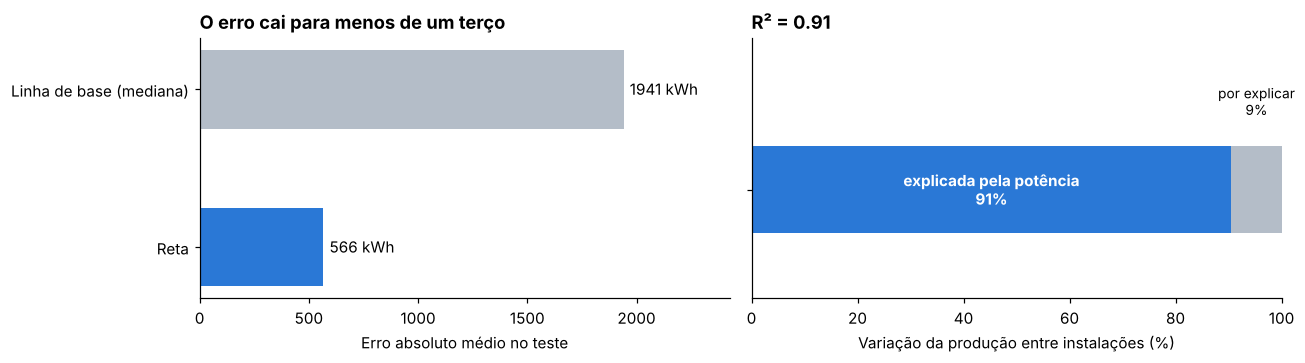

In [10]:
x_teste, y_teste = teste["potencia_kwp"].to_numpy(), teste["producao_kwh"].to_numpy()
previsto = a + b * x_teste
r2 = 1 - np.sum((y_teste - previsto) ** 2) / np.sum((y_teste - y_teste.mean()) ** 2)
mae, mae_base = np.abs(y_teste - previsto).mean(), np.abs(y_teste - np.median(y)).mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.4))
barras = ax1.barh(["Linha de base (mediana)", "Reta"], [mae_base, mae], color=[CINZA, AZUL], height=0.5)
ax1.bar_label(barras, fmt="%.0f kWh", padding=4)
ax1.invert_yaxis()
ax1.set_xlim(0, mae_base * 1.25)
ax1.set_xlabel("Erro absoluto médio no teste")
ax1.set_title("O erro cai para menos de um terço")
ax2.barh([""], [r2 * 100], color=AZUL, height=0.4)
ax2.barh([""], [(1 - r2) * 100], left=[r2 * 100], color=CINZA, height=0.4)
ax2.text(r2 * 50, 0, f"explicada pela potência\n{r2:.0%}", ha="center", va="center", color="white", fontweight="bold")
ax2.text(r2 * 100 + (1 - r2) * 50, 0.33, f"por explicar\n{1 - r2:.0%}", ha="center", va="bottom", fontsize=9)
ax2.set_xlim(0, 100)
ax2.set_ylim(-0.5, 0.7)
ax2.set_xlabel("Variação da produção entre instalações (%)")
ax2.set_title(f"R² = {r2:.2f}")
plt.tight_layout()
plt.show()

Com uma só coluna, a reta explica cerca de 90% da variação da produção entre instalações, e erra em média perto de 570 kWh. Para uma instalação típica, que produz 5 000 kWh, é um erro de mais de 10%: demasiado para prometer uma poupança a um cliente. Os 10% por explicar estão nas outras colunas, que usaremos no próximo capítulo.

Com um só atributo, o R² é o quadrado da correlação. Três cuidados com ele:

- depende de **quanto varia** o alvo nos dados: o mesmo modelo tem um R² mais baixo num conjunto de instalações todas parecidas;
- um R² alto **não quer dizer** que a relação é uma reta (ver a secção seguinte);
- um R² baixo não quer dizer que o modelo é inútil: em fenómenos com muito ruído, explicar 20% pode valer muito.

## Os resíduos: o que a reta não viu

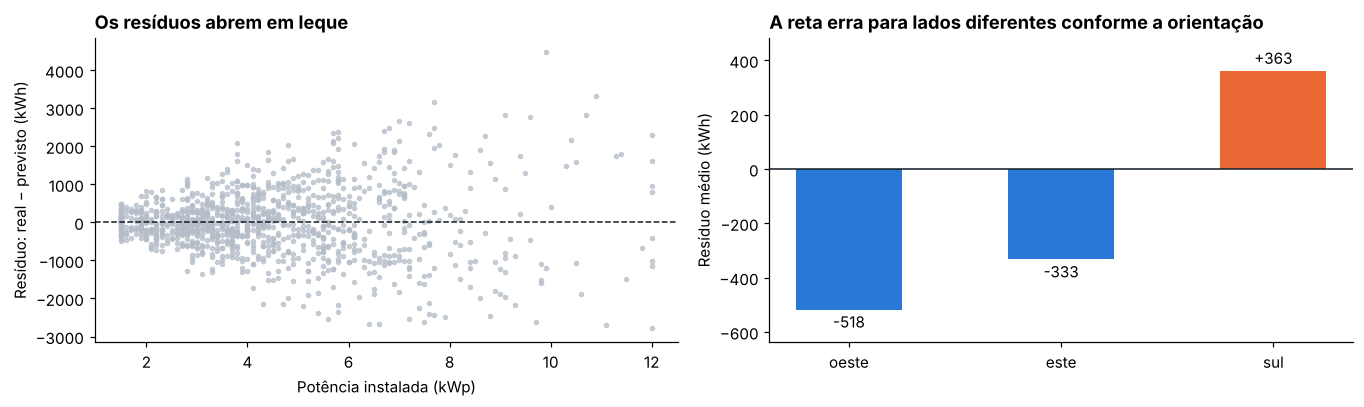

In [11]:
residuos = y - (a + b * x)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 3.8))
ax1.scatter(x, residuos, s=7, color=CINZA, alpha=0.7)
ax1.axhline(0, color=TINTA, lw=1, ls="--")
ax1.set_xlabel("Potência instalada (kWp)")
ax1.set_ylabel("Resíduo: real − previsto (kWh)")
ax1.set_title("Os resíduos abrem em leque")
grupos = treino.assign(residuo=residuos).groupby("orientacao")["residuo"].mean().sort_values()
barras = ax2.bar(grupos.index, grupos, color=[LARANJA if v > 0 else AZUL for v in grupos], width=0.5)
ax2.bar_label(barras, fmt="%+.0f", padding=2)
ax2.axhline(0, color=TINTA, lw=1)
ax2.set_ylim(grupos.min() - 120, grupos.max() + 120)
ax2.set_ylabel("Resíduo médio (kWh)")
ax2.set_title("A reta erra para lados diferentes conforme a orientação")
plt.tight_layout()
plt.show()

Dois padrões:

- **O leque** (à esquerda). Os resíduos são pequenos nas instalações pequenas e grandes nas grandes. O erro não tem o mesmo tamanho em toda a parte: é **proporcional** à produção. É um sinal de que os efeitos aqui se multiplicam em vez de se somarem; voltaremos a ele no capítulo 2.
- **Os grupos** (à direita). A reta subestima os telhados virados a sul e sobrestima os outros. A orientação tem informação que a reta não usa.

Resíduos sem padrão são o sinal de que o modelo aproveitou o que havia para aproveitar. Aqui há padrões, e eles dizem **o que acrescentar** ao modelo.

## Quando uma reta engana

O mesmo declive e o mesmo R² podem sair de dados muito diferentes. Quatro conjuntos inventados, todos com a mesma reta dos mínimos quadrados:

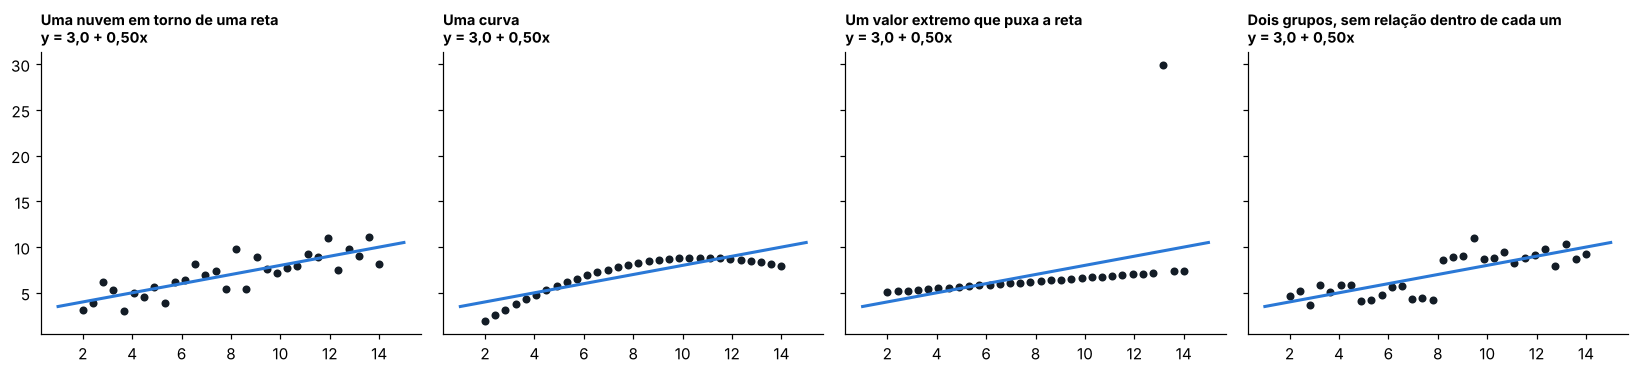

In [12]:
rng = np.random.default_rng(4)
u = np.linspace(2, 14, 30)


def ajustar_a_reta(u, v, declive=0.5, ordenada=3.0):
    """Corrige v para que a sua reta dos mínimos quadrados seja exatamente a pretendida."""
    a0, b0 = reta_dos_minimos_quadrados(u, v)
    return v - (a0 + b0 * u) + ordenada + declive * u


casos = {"Uma nuvem em torno de uma reta": 0.5 * u + rng.normal(0, 1.1, 30),
         "Uma curva": -0.09 * (u - 11) ** 2,
         "Um valor extremo que puxa a reta": np.where(np.arange(30) == 27, 26.0, 0.25 * u),
         "Dois grupos, sem relação dentro de cada um": np.where(u < 8, 0, 4.2) + rng.normal(0, 0.9, 30)}

fig, eixos = plt.subplots(1, 4, figsize=(15, 3.5), sharey=True)
for ax, (titulo, v) in zip(eixos, casos.items()):
    v = ajustar_a_reta(u, v)
    a_c, b_c = reta_dos_minimos_quadrados(u, v)
    ax.scatter(u, v, s=18, color=TINTA)
    ax.plot([1, 15], [a_c + b_c, a_c + b_c * 15], color=AZUL, lw=2)
    ax.set_title(f"{titulo}\ny = {a_c:.1f} + {b_c:.2f}x".replace(".", ","), fontsize=9.5)
plt.tight_layout()
plt.show()

As quatro retas são **iguais**. Só a primeira descreve bem os dados.

- Na segunda, a relação é curva: a reta acerta em média e erra de forma sistemática em cada zona.
- Na terceira, um único ponto mudou a reta. Por causa dos quadrados, um valor extremo puxa a reta com muita força.
- Na quarta, não há relação dentro de cada grupo: a reta liga apenas dois montes de pontos.

Nenhum destes problemas se vê no declive ou no R². Vê-se no **gráfico**. É a lição do módulo 3, capítulo 4: desenhar antes de calcular.

### Não prever fora dos dados

A reta está definida para qualquer valor de x, mas só foi verificada nos valores que os dados cobrem.

In [13]:
print(f"Potências no treino: de {x.min()} a {x.max()} kWp")
for potencia in [5, 12, 40, 300]:
    print(f"  {potencia:>3} kWp → previsão: {a + b * potencia:>9,.0f} kWh".replace(",", " "))

Potências no treino: de 1.5 a 12.0 kWp
    5 kWp → previsão:     5 614 kWh
   12 kWp → previsão:    13 486 kWh
   40 kWp → previsão:    44 975 kWh
  300 kWp → previsão:   337 378 kWh


A previsão para 300 kWp é um número com bom aspeto, e não tem fundamento: uma instalação desse tamanho é um parque industrial, com outros equipamentos e outras perdas. A reta **extrapola** sem avisar. Dentro do intervalo dos dados, prever é **interpolar**, e é para isso que o modelo serve.

## Exercícios

### `Exercício 1` – Uma reta à mão

Cinco instalações têm as potências 2, 3, 4, 5 e 6 kWp e produziram 2,4; 3,3; 4,6; 5,4 e 6,8 MWh. Calcula as médias, a covariância, a variância de x, o declive e a ordenada na origem. Qual é a previsão para 4,5 kWp?

<details>
<summary><b>Ver uma solução possível</b></summary>

- Médias: x = 4; y = 4,5.
- Desvios de x: −2, −1, 0, 1, 2. Desvios de y: −2,1; −1,2; 0,1; 0,9; 2,3.
- Covariância = (4,2 + 1,2 + 0 + 0,9 + 4,6) ÷ 5 = 10,9 ÷ 5 = **2,18**.
- Variância de x = (4 + 1 + 0 + 1 + 4) ÷ 5 = **2**.
- Declive b = 2,18 ÷ 2 = **1,09** MWh por kWp.
- Ordenada a = 4,5 − 1,09 × 4 = **0,14**.
- Previsão para 4,5 kWp: 0,14 + 1,09 × 4,5 ≈ **5,05 MWh**.

</details>

### `Exercício 2` – Outro atributo

Ajusta uma reta para prever a produção a partir de `sombra_pct` (em vez da potência). Qual é o declive, e o que significa? Qual é o R² no teste? Porque é tão diferente do da potência?

In [14]:
# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
a_s, b_s = reta_dos_minimos_quadrados(treino["sombra_pct"].to_numpy(), y)
previsto_s = a_s + b_s * teste["sombra_pct"].to_numpy()
r2_s = 1 - np.sum((y_teste - previsto_s) ** 2) / np.sum((y_teste - y_teste.mean()) ** 2)
print(f"produção = {a_s:.0f} {b_s:+.0f} × sombra | R² no teste: {r2_s:.3f}")
```

O declive é negativo: cada ponto percentual de sombra a mais corresponde a umas dezenas de kWh a menos por ano. Mas o R² é muito baixo. A sombra tem efeito, e esse efeito é pequeno ao lado das diferenças de **tamanho** entre instalações, que esta reta ignora. Um atributo pode ser relevante e, sozinho, explicar pouco. No próximo capítulo, ao lado da potência, a sombra vai mostrar o que vale.

</details>

### `Exercício 3` – O efeito de um valor extremo

Acrescenta ao treino uma instalação fictícia de 11 kWp que produziu apenas 500 kWh (um inversor avariado o ano todo). Recalcula a reta. Quanto mudou o declive? Repete com 200 instalações de treino em vez de todas. O que concluis?

In [15]:
# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
for n in [len(x), 200]:
    xn, yn = x[:n], y[:n]
    antes = reta_dos_minimos_quadrados(xn, yn)[1]
    depois = reta_dos_minimos_quadrados(np.append(xn, 11.0), np.append(yn, 500.0))[1]
    print(f"{n:>4} instalações: declive {antes:.0f} → {depois:.0f} ({(depois / antes - 1):+.1%})")
```

Com mais de mil instalações, um único ponto mexe pouco no declive. Com 200, o efeito é várias vezes maior. Um valor extremo pesa tanto mais quanto menos dados houver, e quanto mais longe estiver do centro em x (um ponto na ponta da reta funciona como uma alavanca). Antes de ajustar uma reta, vale a pena procurar estes pontos e perceber o que são.

</details>

### `Exercício 4` – Uma reta por zona

Ajusta uma reta (produção em função da potência) para cada zona do país. Os declives são iguais? O que representa a diferença?

In [16]:
# Escreve aqui o código do exercício 4

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
for zona, grupo in treino.groupby("zona"):
    az, bz = reta_dos_minimos_quadrados(grupo["potencia_kwp"].to_numpy(), grupo["producao_kwh"].to_numpy())
    print(f"{zona:>6}: produção = {az:>5.0f} + {bz:.0f} × potência   ({len(grupo)} instalações)")
```

O declive cresce de norte para sul: o mesmo quilowatt produz mais onde há mais sol. A diferença entre zonas não é um valor fixo que se soma: é uma diferença no **próprio declive**. O efeito da potência depende da zona. A isto chama-se uma **interação**, e uma única reta para todo o país não a consegue representar.

</details>

## Verifica o que aprendeste

- [ ] Sei escrever a equação de uma reta e interpretar o declive e a ordenada na origem.
- [ ] Sei o que é um resíduo e porque se somam os quadrados.
- [ ] Sei calcular a reta dos mínimos quadrados com a covariância e a variância.
- [ ] Sei relacionar o declive com a correlação.
- [ ] Sei calcular e interpretar o R².
- [ ] Sei usar os resíduos para ver o que falta ao modelo.
- [ ] Sei porque é preciso desenhar os dados antes de confiar numa reta.
- [ ] Sei distinguir interpolar de extrapolar.

## Leitura recomendada

- https://scikit-learn.org/stable/modules/linear_model.html#ordinary-least-squares
- https://en.wikipedia.org/wiki/Simple_linear_regression
- https://en.wikipedia.org/wiki/Anscombe%27s_quartet